# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.2. Regresión lineal múltiple y predicción

*Bienvenidos* a este jupyter notebook que nos será de utilidad para comprender la regresión lineal.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Importación de bibliotecas

In [1]:
import warnings
warnings.filterwarnings("ignore")

#Cargar bibliotecas esenciales para el análisis de datos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 1.26.4
pandas: 3.0.6
seaborn: 0.13.2
Matplotlib: 3.11.2


#### Carga y exploración inicial de los datos

In [2]:
import pandas as pd
data = pd.read_csv("boston_housing.csv")
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [3]:
data.shape

(506, 14)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  PRICE    506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB


#### Separación de los datos de entrenamiento y prueba

In [5]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(data, train_size=0.7, random_state=42)

print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

Entrenamiento: (354, 14)
Prueba: (152, 14)


#### Construcción, ajuste e interpretación del modelo de regresión lineal múltiple

In [6]:
import statsmodels.api as sm
x = train.drop(['PRICE'], axis = 1)
y = train.PRICE

X = sm.add_constant(x)
model = sm.OLS(y, X)

results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  PRICE   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     75.81
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           4.96e-92
Time:                        00:37:19   Log-Likelihood:                -1053.8
No. Observations:                 354   AIC:                             2136.
Df Residuals:                     340   BIC:                             2190.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         31.6311      6.056      5.223      0.000      19.720      43.542
CRIM          -0.1335      0.041     -3.271      0.001      -0.214      -0.053
ZN             0.0358      0.018      2.029      0.043       0.001       0.071
INDUS          0.0495      0.073      0.680      0.497      -0.094       0.193
CHAS           3.1198      1.037      3.010      0.003       1.081       5.159
NOX          -15.4171      4.750     -3.246      0.001     -24.759      -6.075
RM             4.0572      0.496      8.181      0.000       3.082       5.033
AGE           -0.0108      0.016     -0.671      0.503      -0.043       0.021
DIS           -1.3860      0.242     -5.734      0.000      -1.861      -0.911
RAD            0.2427      0.082      2.963      0.003       0.082       0.404
TAX           -0.0087      0.005     -1.886      0.060      -0.018       0.000
PTRATIO       -0.9107      0.154     -5.905      0.000      -1.214      -0.607
B              0.0118      0.003      3.534      0.000       0.005       0.018
LSTAT         -0.5471      0.059     -9.219      0.000      -0.664      -0.430
==============================================================================
Omnibus:                      115.779   Durbin-Watson:                   2.087
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              458.270
Skew:                           1.381   Prob(JB):                    3.08e-100
Kurtosis:                       7.842   Cond. No.                     1.49e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.49e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Significancia estadística de los coeficientes

In [7]:
results.pvalues

const      3.069062e-07
CRIM       1.182004e-03
ZN         4.325030e-02
INDUS      4.967706e-01
CHAS       2.809115e-03
NOX        1.286777e-03
RM         5.681360e-15
AGE        5.028814e-01
DIS        2.164074e-08
RAD        3.263905e-03
TAX        6.016873e-02
PTRATIO    8.564091e-09
B          4.659223e-04
LSTAT      3.221394e-18
dtype: float64

#### Evaluación del error en entrenamiento: RMSE y RSE

In [8]:
residuos = results.resid

rmse = np.sqrt(np.mean(residuos**2))
rse = np.sqrt(results.ssr / results.df_resid)

print(f"RMSE de entrenamiento: {rmse:.4f}")
print(f"RSE de entrenamiento: {rse:.4f}")
print(f"R² de entrenamiento: {results.rsquared:.4f}")

RMSE de entrenamiento: 4.7482
RSE de entrenamiento: 4.8450
R² de entrenamiento: 0.7435


#### Predicción con los datos de prueba

In [9]:
xTest = test.drop(["PRICE"], axis=1)
yTest = test.PRICE

XTest = sm.add_constant(xTest)
yHat = results.predict(XTest)

#### Comparación de valores reales y predichos

In [10]:
comparacion = pd.DataFrame({
    "Precio real": yTest,
    "Precio predicho": yHat
})

comparacion.head(10)

,Precio real,Precio predicho
173,23.6,28.648960
274,32.4,36.495014
491,13.6,15.411193
72,22.8,25.403213
452,16.1,18.855280
76,20.0,23.146689
316,17.8,17.392124
140,14.0,14.078599
471,19.6,23.036927
500,16.8,20.599433


#### Evaluación de las predicciones: RMSE y R2

In [11]:
errores = yTest - yHat

rmseTest = np.sqrt(np.mean(errores**2))

rssTest = np.sum(errores**2)
tssTest = np.sum((yTest - yTest.mean())**2)
r2Test = 1 - rssTest / tssTest

print(f"RMSE de prueba: {rmseTest:.4f}")
print(f"R² de prueba: {r2Test:.4f}")

RMSE de prueba: 4.6387
R² de prueba: 0.7112


#### Visualización de los valores reales y predichos

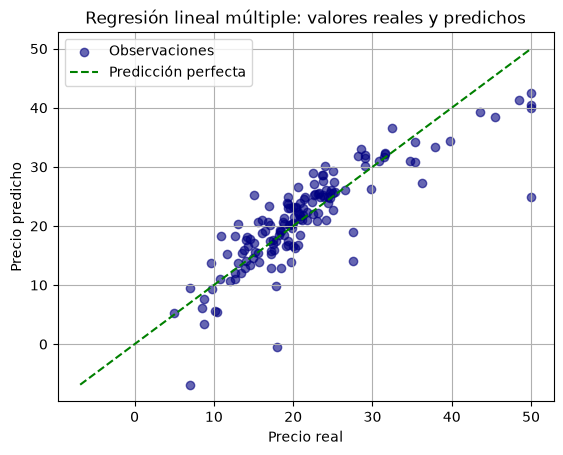

In [12]:
plt.scatter(
    yTest, yHat,
    label="Observaciones",
    color="navy",
    alpha=0.6
)

minimo = min(yTest.min(), yHat.min())
maximo = max(yTest.max(), yHat.max())

plt.plot(
    [minimo, maximo], [minimo, maximo],
    color="green",
    linestyle="--",
    label="Predicción perfecta"
)

plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.title("Regresión lineal múltiple: valores reales y predichos")
plt.legend()
plt.grid()
plt.show()